### model training with global prior.
#### Note: 
1. train global surface water mapping model.    
2. using global prior for local patch-based model training. 



In [5]:
import time
import torch
import random
import numpy as np 
import torch.nn as nn
from glob import glob
from pyrsimg import imsShow
from processing import config
import matplotlib.pyplot as plt
import torch.nn.functional as F
from utils.utils import read_imgs
from torchvision.transforms import v2
from dataloader.data_aug import GaussianNoise
from dataloader.data_loader import SceneArraySet_2, PatchPathSet 
from torchmetrics.classification import MulticlassJaccardIndex, BinaryAccuracy   
from model import unet_backbone_timm    
from model import unet, unet_att, deeplabv3plus_mobilev2, swin_unet, watnet  
from model.mamba_seg.mamba_seg import MambaSeg  
from model.mamba_seg.mamba_seg_gfusion import MambaSeg_gfusion   
from pathlib import Path   


/home/ps/miniconda3/envs/watnet-luo/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
patch_size = 256           ## patch size setting
patch_resize = None        ## patch resize setting
learning_rate = 1e-4     
batch_size = 16
device = torch.device('cuda:0')    


In [7]:
### traset
paths_tra_scene = config.paths_tra_scene    
paths_tra_truth = config.paths_tra_truth     
dir_tra_gfea = Path('data/dset/train/scene_global_fea/')      
paths_tra_gfea = sorted(dir_tra_gfea.glob('*'))            
print(f'train_scenes: {len(paths_tra_scene)}')         


train_scenes: 172


### dataset loading

In [8]:
## tradata  
tra_scenes_arr, tra_gfeas_arr, tra_truths_arr = read_imgs(paths_tra_scene, paths_tra_gfea, paths_tra_truth) 
tra_gfeas_arr = [gfea for gfea in tra_gfeas_arr]
tra_sgtruth_ls =  list(zip(tra_scenes_arr, tra_gfeas_arr, tra_truths_arr))
tra_sgtruth_ls = [np.concatenate([scene, gfea, truth], axis=-1) 
                                            for scene, gfea, truth in tra_sgtruth_ls] 
## valdata   
paths_valset = sorted(glob(f'data/dset/val_patch/patch_{patch_size}_gfea/*'))  ## for model prediction 
print(f'vali_patch_{patch_size}: {len(paths_valset)}')


vali_patch_256: 1722


In [9]:
# global prior inference model training  
transforms_tra = v2.Compose([
      v2.RandomCrop(size=(patch_size, patch_size), padding = 50),
      v2.RandomApply([v2.RandomRotation(degrees=15)], p=0.3),
      v2.RandomHorizontalFlip(p=0.3),
      v2.RandomVerticalFlip(p=0.3),
      # GaussianNoise(mean=0, sigma_max=0.05, p=0.3),   ## better than v2.GaussianNoise()  
       ])


In [10]:
tra_dset = SceneArraySet_2(scene_gfea_truth_list = tra_sgtruth_ls, 
                           transforms = transforms_tra,
                           noise = GaussianNoise(mean=0, sigma_max=0.05, p=0.3))
val_dset = PatchPathSet(paths_valset=paths_valset, transforms=None)
### Create DataLoader
tra_loader = torch.utils.data.DataLoader(tra_dset, batch_size=batch_size,   
                                                      shuffle=True, num_workers=4)     
val_loader = torch.utils.data.DataLoader(val_dset, batch_size=32, num_workers=5)     


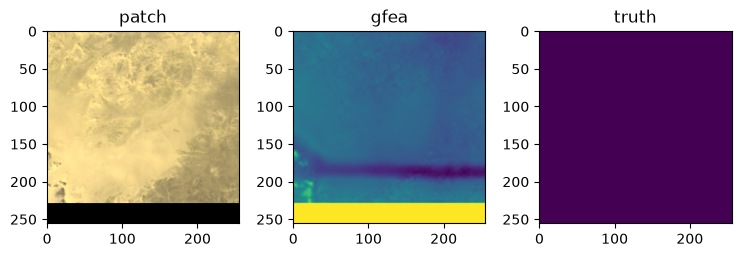

In [11]:
## show train/validation data.    
i = random.randint(0, len(tra_dset)-1)
patch_gfea, truth = tra_dset[i]
patch, gfea = patch_gfea[:6], patch_gfea[6:7]
imsShow([patch.numpy().transpose(1,2,0), gfea.numpy().transpose(1,2,0), truth.numpy().transpose(1,2,0)],
            clip_list = (2,0,0),
            img_name_list=['patch', 'gfea', 'truth'], 
            color_bands_list=([3,2,1], [0,0,0], [0,0,0]),              
            figsize=(9, 2.5));   


#### Model training

In [12]:
### check model
# model = unet(num_bands=6)
# model = watnet(num_bands=6)
## model with pretrained 
# # for cnn backbone
# model = unet_backbone_timm(num_bands=6, 
#                          backbone_name='efficientnet_b0', 
#                         # backbone_name='mobilenetv3_large_100',
#                         # backbone_name='resnet50',
#                           # backbone_name='vit_large_patch16_dinov3.sat493m',
#                           # backbone_name='vit_small_plus_patch16_dinov3.lvd1689m',
#                           pretrained=True,
#                           ).to('cuda')

## for swin transformer backbone（img_size setting is required.）      
# model = unet_backbone_timm(num_bands=6, 
#                          img_size = 512, 
#                          backbone_name='swinv2_base_window8_256',
#                          pretrained=True).to('cuda')
### mamba backbone  
model = MambaSeg_gfusion(
        in_chans_local=6,
        in_chans_global=1, 
        num_classes=1, 
        decoder_chans=32,
        dims=96, 
        depths=(2, 2, 8, 2), 
        # backend='torch',
        backend='oflex', 
        pretrained = True,
        ).to('cuda')

model_name = 'unet_mamba_pretrain_global_l256'  ## model name for saving  


Loaded model/weights/vssm1_tiny_0230s_ckpt_epoch_264.pth; newly initialized output norms: ['outnorm0.weight', 'outnorm0.bias', 'outnorm1.weight', 'outnorm1.bias', 'outnorm2.weight', 'outnorm2.bias', 'outnorm3.weight', 'outnorm3.bias']


In [15]:
input_tensor = torch.randn(2, 7, 256, 256, device='cuda')
output = model(input_tensor)
print(output.shape)


torch.Size([2, 1, 256, 256])


In [16]:
### create loss and optimizer
bce_loss = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)  
# lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, \
#                                       mode='max', 
#                                       factor=0.5, 
#                                       patience=10,
#                                       min_lr=1e-5)


In [17]:
sam_index = random.randrange(len(val_dset))
patch_val, truth_val = val_dset[sam_index]
def show_result(model, patch, truth):
    model.eval()
    device = next(model.parameters()).device
    patch, truth = patch.unsqueeze(0).to(device), truth.to(device)
    pred = model(patch) 
    pred = F.sigmoid(pred)   ## convert to probability
    ## convert to numpy and plot
    patch = patch[0].to('cpu').detach().numpy().transpose(1,2,0)            
    pred = pred[0].to('cpu').detach().numpy()
    truth = truth[0].to('cpu').detach().numpy()
    imsShow([patch, pred, truth],   
            clip_list = (2,0,0),
            img_name_list=['patch', 'pred', 'truth'], 
            color_bands_list=([3,2,1], 0, 0),                    
            figsize=(9, 2.5))
    plt.tight_layout() 
    plt.show()   


In [18]:
'''------train loops------'''
def train_loops(model, loss_fn, 
                    optimizer, 
                    tra_loader, 
                    val_loader,  
                    epoches, 
                    device, 
                    lr_scheduler=None):
    loss_tra_loops, miou_tra_loops, oa_tra_loops = [], [], []
    loss_val_loops, miou_val_loops, oa_val_loops = [], [], []
    model = model.to(device)
    size_tra_loader = len(tra_loader)
    size_val_loader = len(val_loader)
    best_miou = 0.92
    epoches_i = []
    for epoch in range(epoches):
        start = time.time()
        loss_tra, loss_val = 0, 0
        '''-----train the model-----'''
        oa_tra = BinaryAccuracy().to(device)
        miou_tra = MulticlassJaccardIndex(num_classes=2, average="macro").to(device)
        model.train()   # training mode for dropout and batchnorm
        for x_batch, y_batch in tra_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(x_batch)
            loss = loss_fn(pred, y_batch)
            loss.backward()
            optimizer.step()
            pred = (F.sigmoid(pred) > 0.5).float()
            miou_tra.update(pred, y_batch.long())
            oa_tra.update(pred, y_batch.long())
            loss_tra += loss.item()
        miou_tra_global = miou_tra.compute()
        oa_tra_global = oa_tra.compute()
        loss_tra_global = loss_tra/size_tra_loader
        miou_tra.reset(); oa_tra.reset()

        '''----- validation the model: time consuming -----'''
        oa_val = BinaryAccuracy().to(device)
        miou_val = MulticlassJaccardIndex(num_classes=2, average="macro").to(device)
        model.eval()
        if epoch > 100 and (epoch+1) % 2 == 0: 
            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                with torch.no_grad():
                    pred = model(x_batch)
                    loss = loss_fn(pred, y_batch)
                pred = (F.sigmoid(pred) > 0.5).long()
                miou_val.update(pred, y_batch.long())
                oa_val.update(pred, y_batch.long())
                loss_val += loss.item()
            miou_val_global = miou_val.compute()
            oa_val_global = oa_val.compute()
            loss_val_global = loss_val/size_val_loader
            miou_val.reset(); oa_val.reset()
            loss_tra_loops.append(loss_tra_global); miou_tra_loops.append(miou_tra_global.item()); oa_tra_loops.append(oa_tra_global.item())
            loss_val_loops.append(loss_val_global); miou_val_loops.append(miou_val_global.item()); oa_val_loops.append(oa_val_global.item())
            epoches_i.append(epoch)
            print(f'Ep{epoch}: tra-> Loss:{loss_tra_global:.3f},Oa:{oa_tra_global:.3f},Miou:{miou_tra_global:.3f}, '
                    f'val-> Loss:{loss_val_global:.4f},Oa:{oa_val_global:.4f}, Miou:{miou_val_global:.4f},time:{time.time()-start:.1f}s')
            ## save the best model
            if miou_val_global.item() > best_miou:
                best_miou = miou_val_global.item()       ## update best miou
                torch.save(model.state_dict(), f'model/trained/{model_name}_epoch_{epoch}_0{str(round(best_miou*10000))}.pth')
        else: 
            print(f'Ep{epoch}: tra-> Loss:{loss_tra_global:.3f},Oa:{oa_tra_global:.3f},Miou:{miou_tra_global:.3f}, \
                                time:{time.time()-start:.1f}s')
        if lr_scheduler: lr_scheduler.step(miou_tra_global)    ## if use lr_scheduler like ReduceLROnPlateau
        if (epoch+1)%50 == 0:
            sam_index = random.randrange(len(val_dset))
            patch_val, truth_val = val_dset[sam_index] 
            show_result(model=model, patch=patch_val, truth=truth_val)   
    metrics = {'epoch':epoches_i, 'tra_loss':loss_tra_loops, 'tra_oa': oa_tra_loops, 'tra_miou': miou_tra_loops,
                'val_loss': loss_val_loops, 'val_oa': oa_val_loops, 'val_miou': miou_val_loops}
    return metrics  


Ep0: tra-> Loss:0.018,Oa:0.993,Miou:0.975,                                 time:4.8s
Ep1: tra-> Loss:0.018,Oa:0.992,Miou:0.977,                                 time:4.4s
Ep2: tra-> Loss:0.017,Oa:0.993,Miou:0.980,                                 time:4.5s
Ep3: tra-> Loss:0.019,Oa:0.992,Miou:0.980,                                 time:4.6s
Ep4: tra-> Loss:0.016,Oa:0.993,Miou:0.978,                                 time:4.6s
Ep5: tra-> Loss:0.017,Oa:0.993,Miou:0.980,                                 time:4.7s
Ep6: tra-> Loss:0.017,Oa:0.993,Miou:0.980,                                 time:4.6s
Ep7: tra-> Loss:0.018,Oa:0.992,Miou:0.976,                                 time:4.6s
Ep8: tra-> Loss:0.018,Oa:0.993,Miou:0.977,                                 time:4.6s
Ep9: tra-> Loss:0.017,Oa:0.993,Miou:0.978,                                 time:4.8s
Ep10: tra-> Loss:0.017,Oa:0.993,Miou:0.977,                                 time:4.6s
Ep11: tra-> Loss:0.018,Oa:0.993,Miou:0.977,                     

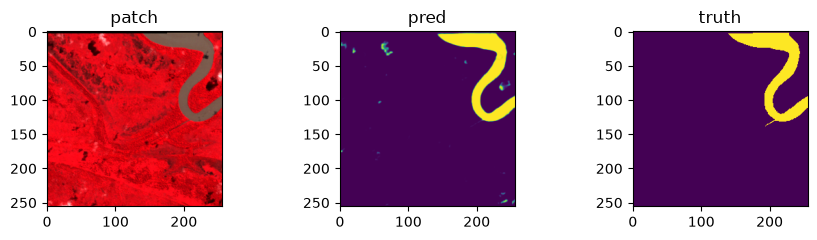

Ep50: tra-> Loss:0.016,Oa:0.993,Miou:0.978,                                 time:4.5s
Ep51: tra-> Loss:0.017,Oa:0.993,Miou:0.978,                                 time:4.5s
Ep52: tra-> Loss:0.015,Oa:0.994,Miou:0.980,                                 time:4.5s
Ep53: tra-> Loss:0.016,Oa:0.993,Miou:0.977,                                 time:4.5s
Ep54: tra-> Loss:0.016,Oa:0.993,Miou:0.979,                                 time:4.4s
Ep55: tra-> Loss:0.017,Oa:0.993,Miou:0.980,                                 time:4.6s
Ep56: tra-> Loss:0.016,Oa:0.993,Miou:0.978,                                 time:4.6s
Ep57: tra-> Loss:0.017,Oa:0.993,Miou:0.977,                                 time:4.5s
Ep58: tra-> Loss:0.016,Oa:0.993,Miou:0.980,                                 time:4.7s
Ep59: tra-> Loss:0.018,Oa:0.992,Miou:0.976,                                 time:4.8s
Ep60: tra-> Loss:0.016,Oa:0.993,Miou:0.977,                                 time:4.6s
Ep61: tra-> Loss:0.016,Oa:0.993,Miou:0.979,           

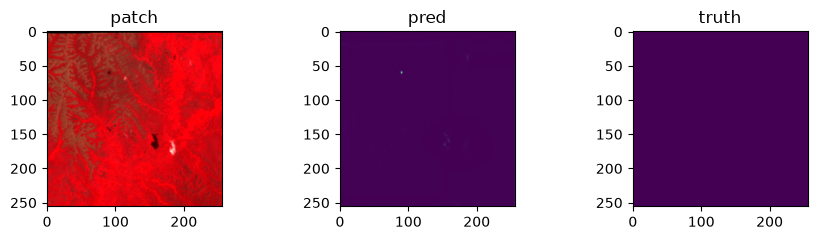

Ep100: tra-> Loss:0.015,Oa:0.994,Miou:0.982,                                 time:4.7s
Ep101: tra-> Loss:0.017,Oa:0.993,Miou:0.977, val-> Loss:0.0340,Oa:0.9885, Miou:0.9630,time:13.9s
Ep102: tra-> Loss:0.016,Oa:0.993,Miou:0.981,                                 time:4.5s
Ep103: tra-> Loss:0.018,Oa:0.992,Miou:0.976, val-> Loss:0.0334,Oa:0.9886, Miou:0.9634,time:13.6s
Ep104: tra-> Loss:0.016,Oa:0.993,Miou:0.979,                                 time:4.3s
Ep105: tra-> Loss:0.016,Oa:0.993,Miou:0.979, val-> Loss:0.0332,Oa:0.9886, Miou:0.9633,time:13.5s
Ep106: tra-> Loss:0.015,Oa:0.994,Miou:0.979,                                 time:4.9s
Ep107: tra-> Loss:0.018,Oa:0.993,Miou:0.976, val-> Loss:0.0338,Oa:0.9886, Miou:0.9633,time:13.7s
Ep108: tra-> Loss:0.016,Oa:0.993,Miou:0.979,                                 time:4.4s
Ep109: tra-> Loss:0.016,Oa:0.993,Miou:0.979, val-> Loss:0.0331,Oa:0.9886, Miou:0.9633,time:13.7s
Ep110: tra-> Loss:0.017,Oa:0.993,Miou:0.977,                                 tim

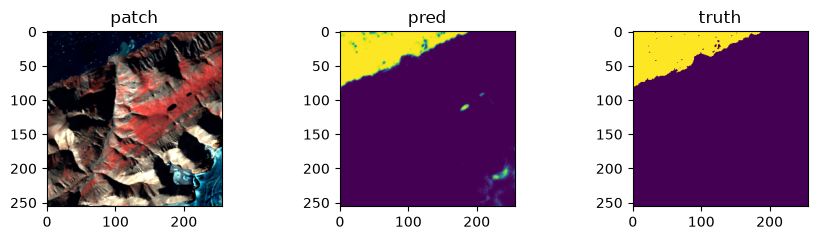

Ep150: tra-> Loss:0.017,Oa:0.993,Miou:0.980,                                 time:4.4s
Ep151: tra-> Loss:0.017,Oa:0.993,Miou:0.976, val-> Loss:0.0345,Oa:0.9883, Miou:0.9622,time:13.8s
Ep152: tra-> Loss:0.017,Oa:0.993,Miou:0.980,                                 time:4.5s
Ep153: tra-> Loss:0.015,Oa:0.994,Miou:0.981, val-> Loss:0.0341,Oa:0.9887, Miou:0.9635,time:13.6s
Ep154: tra-> Loss:0.016,Oa:0.993,Miou:0.978,                                 time:4.5s
Ep155: tra-> Loss:0.016,Oa:0.993,Miou:0.978, val-> Loss:0.0337,Oa:0.9886, Miou:0.9632,time:13.5s
Ep156: tra-> Loss:0.015,Oa:0.994,Miou:0.979,                                 time:4.8s
Ep157: tra-> Loss:0.016,Oa:0.993,Miou:0.979, val-> Loss:0.0338,Oa:0.9887, Miou:0.9636,time:13.9s
Ep158: tra-> Loss:0.018,Oa:0.992,Miou:0.977,                                 time:4.4s
Ep159: tra-> Loss:0.014,Oa:0.994,Miou:0.982, val-> Loss:0.0341,Oa:0.9885, Miou:0.9630,time:13.7s
Ep160: tra-> Loss:0.016,Oa:0.993,Miou:0.980,                                 tim

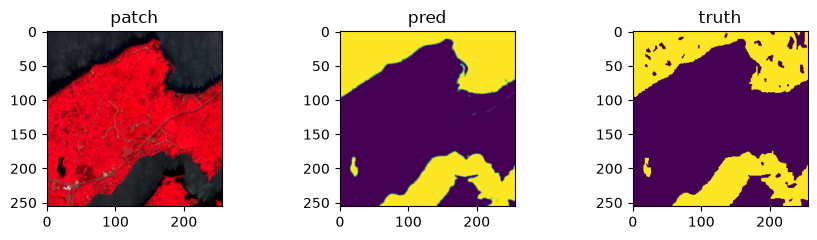

Ep200: tra-> Loss:0.017,Oa:0.993,Miou:0.979,                                 time:4.5s
Ep201: tra-> Loss:0.016,Oa:0.993,Miou:0.980, val-> Loss:0.0340,Oa:0.9886, Miou:0.9632,time:13.7s
Ep202: tra-> Loss:0.017,Oa:0.993,Miou:0.980,                                 time:4.7s
Ep203: tra-> Loss:0.015,Oa:0.994,Miou:0.981, val-> Loss:0.0344,Oa:0.9884, Miou:0.9628,time:13.6s
Ep204: tra-> Loss:0.015,Oa:0.993,Miou:0.980,                                 time:4.5s
Ep205: tra-> Loss:0.016,Oa:0.993,Miou:0.980, val-> Loss:0.0349,Oa:0.9883, Miou:0.9622,time:13.7s
Ep206: tra-> Loss:0.016,Oa:0.994,Miou:0.978,                                 time:4.7s
Ep207: tra-> Loss:0.015,Oa:0.994,Miou:0.982, val-> Loss:0.0344,Oa:0.9884, Miou:0.9628,time:13.7s
Ep208: tra-> Loss:0.016,Oa:0.993,Miou:0.979,                                 time:4.6s
Ep209: tra-> Loss:0.016,Oa:0.993,Miou:0.980, val-> Loss:0.0340,Oa:0.9885, Miou:0.9630,time:13.8s
Ep210: tra-> Loss:0.017,Oa:0.993,Miou:0.978,                                 tim

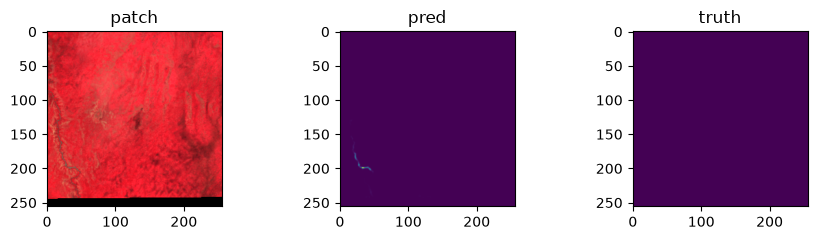

Ep250: tra-> Loss:0.015,Oa:0.994,Miou:0.981,                                 time:4.5s
Ep251: tra-> Loss:0.016,Oa:0.993,Miou:0.978, val-> Loss:0.0340,Oa:0.9886, Miou:0.9631,time:13.5s
Ep252: tra-> Loss:0.016,Oa:0.993,Miou:0.979,                                 time:4.4s
Ep253: tra-> Loss:0.015,Oa:0.994,Miou:0.978, val-> Loss:0.0339,Oa:0.9886, Miou:0.9632,time:13.9s
Ep254: tra-> Loss:0.017,Oa:0.993,Miou:0.979,                                 time:4.6s
Ep255: tra-> Loss:0.016,Oa:0.993,Miou:0.979, val-> Loss:0.0341,Oa:0.9886, Miou:0.9632,time:13.7s
Ep256: tra-> Loss:0.017,Oa:0.993,Miou:0.978,                                 time:4.6s
Ep257: tra-> Loss:0.015,Oa:0.994,Miou:0.981, val-> Loss:0.0351,Oa:0.9885, Miou:0.9629,time:13.7s
Ep258: tra-> Loss:0.017,Oa:0.993,Miou:0.979,                                 time:4.6s
Ep259: tra-> Loss:0.015,Oa:0.994,Miou:0.979, val-> Loss:0.0371,Oa:0.9880, Miou:0.9613,time:13.7s
Ep260: tra-> Loss:0.014,Oa:0.994,Miou:0.980,                                 tim

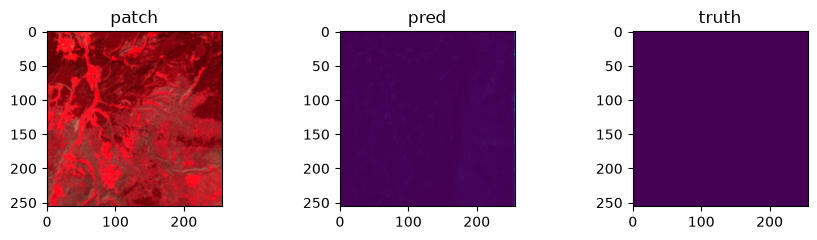

Ep300: tra-> Loss:0.016,Oa:0.993,Miou:0.976,                                 time:4.6s
Ep301: tra-> Loss:0.015,Oa:0.993,Miou:0.981, val-> Loss:0.0358,Oa:0.9881, Miou:0.9616,time:13.9s
Ep302: tra-> Loss:0.016,Oa:0.993,Miou:0.980,                                 time:4.4s
Ep303: tra-> Loss:0.013,Oa:0.994,Miou:0.983, val-> Loss:0.0353,Oa:0.9883, Miou:0.9624,time:13.7s
Ep304: tra-> Loss:0.015,Oa:0.993,Miou:0.978,                                 time:4.6s
Ep305: tra-> Loss:0.017,Oa:0.993,Miou:0.978, val-> Loss:0.0350,Oa:0.9883, Miou:0.9625,time:14.0s
Ep306: tra-> Loss:0.014,Oa:0.994,Miou:0.981,                                 time:4.4s
Ep307: tra-> Loss:0.015,Oa:0.994,Miou:0.982, val-> Loss:0.0339,Oa:0.9888, Miou:0.9640,time:13.9s
Ep308: tra-> Loss:0.015,Oa:0.994,Miou:0.981,                                 time:4.5s
Ep309: tra-> Loss:0.015,Oa:0.994,Miou:0.979, val-> Loss:0.0339,Oa:0.9887, Miou:0.9636,time:13.8s
Ep310: tra-> Loss:0.016,Oa:0.993,Miou:0.978,                                 tim

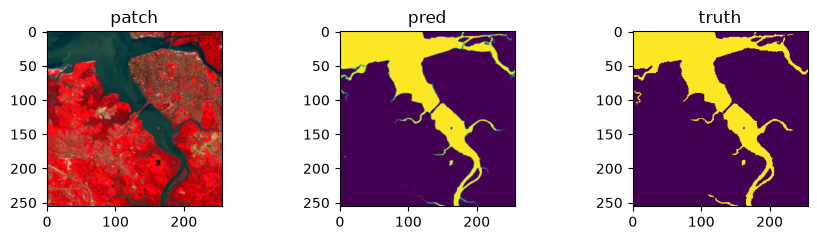

Ep350: tra-> Loss:0.016,Oa:0.993,Miou:0.980,                                 time:4.7s
Ep351: tra-> Loss:0.016,Oa:0.993,Miou:0.979, val-> Loss:0.0339,Oa:0.9891, Miou:0.9650,time:13.7s
Ep352: tra-> Loss:0.017,Oa:0.993,Miou:0.977,                                 time:4.6s
Ep353: tra-> Loss:0.016,Oa:0.993,Miou:0.981, val-> Loss:0.0343,Oa:0.9888, Miou:0.9640,time:13.8s
Ep354: tra-> Loss:0.015,Oa:0.994,Miou:0.980,                                 time:4.6s
Ep355: tra-> Loss:0.016,Oa:0.993,Miou:0.978, val-> Loss:0.0337,Oa:0.9891, Miou:0.9647,time:13.5s
Ep356: tra-> Loss:0.016,Oa:0.993,Miou:0.981,                                 time:4.7s
Ep357: tra-> Loss:0.014,Oa:0.994,Miou:0.981, val-> Loss:0.0369,Oa:0.9882, Miou:0.9620,time:13.7s
Ep358: tra-> Loss:0.015,Oa:0.994,Miou:0.980,                                 time:4.6s
Ep359: tra-> Loss:0.017,Oa:0.993,Miou:0.976, val-> Loss:0.0359,Oa:0.9884, Miou:0.9626,time:13.8s
Ep360: tra-> Loss:0.016,Oa:0.993,Miou:0.979,                                 tim

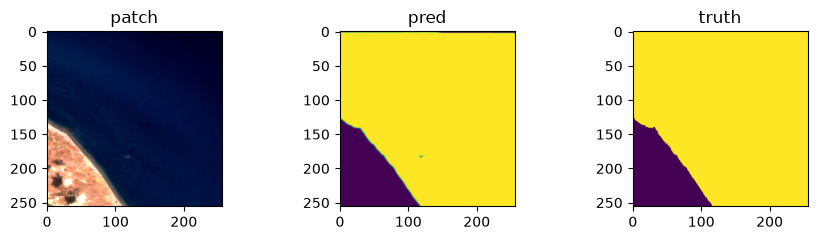

Ep400: tra-> Loss:0.014,Oa:0.994,Miou:0.980,                                 time:4.6s
Ep401: tra-> Loss:0.014,Oa:0.994,Miou:0.982, val-> Loss:0.0364,Oa:0.9883, Miou:0.9622,time:13.5s
Ep402: tra-> Loss:0.015,Oa:0.993,Miou:0.980,                                 time:4.6s
Ep403: tra-> Loss:0.017,Oa:0.993,Miou:0.978, val-> Loss:0.0345,Oa:0.9890, Miou:0.9647,time:13.8s
Ep404: tra-> Loss:0.015,Oa:0.994,Miou:0.981,                                 time:4.6s
Ep405: tra-> Loss:0.016,Oa:0.993,Miou:0.980, val-> Loss:0.0355,Oa:0.9885, Miou:0.9630,time:13.7s
Ep406: tra-> Loss:0.015,Oa:0.994,Miou:0.981,                                 time:4.5s
Ep407: tra-> Loss:0.016,Oa:0.993,Miou:0.979, val-> Loss:0.0348,Oa:0.9886, Miou:0.9632,time:13.9s
Ep408: tra-> Loss:0.017,Oa:0.993,Miou:0.978,                                 time:4.6s
Ep409: tra-> Loss:0.013,Oa:0.995,Miou:0.982, val-> Loss:0.0344,Oa:0.9888, Miou:0.9640,time:14.1s
Ep410: tra-> Loss:0.014,Oa:0.994,Miou:0.980,                                 tim

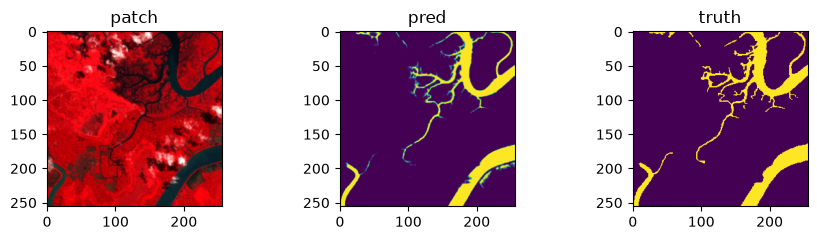

Ep450: tra-> Loss:0.015,Oa:0.994,Miou:0.980,                                 time:4.5s
Ep451: tra-> Loss:0.015,Oa:0.993,Miou:0.980, val-> Loss:0.0353,Oa:0.9887, Miou:0.9635,time:13.9s
Ep452: tra-> Loss:0.015,Oa:0.994,Miou:0.980,                                 time:4.4s
Ep453: tra-> Loss:0.014,Oa:0.994,Miou:0.982, val-> Loss:0.0361,Oa:0.9886, Miou:0.9632,time:13.8s
Ep454: tra-> Loss:0.015,Oa:0.994,Miou:0.980,                                 time:4.6s
Ep455: tra-> Loss:0.015,Oa:0.994,Miou:0.978, val-> Loss:0.0358,Oa:0.9886, Miou:0.9632,time:13.9s
Ep456: tra-> Loss:0.014,Oa:0.994,Miou:0.979,                                 time:4.5s
Ep457: tra-> Loss:0.015,Oa:0.994,Miou:0.979, val-> Loss:0.0358,Oa:0.9886, Miou:0.9634,time:13.6s
Ep458: tra-> Loss:0.014,Oa:0.994,Miou:0.980,                                 time:4.4s
Ep459: tra-> Loss:0.015,Oa:0.994,Miou:0.980, val-> Loss:0.0352,Oa:0.9888, Miou:0.9638,time:13.6s
Ep460: tra-> Loss:0.016,Oa:0.993,Miou:0.979,                                 tim

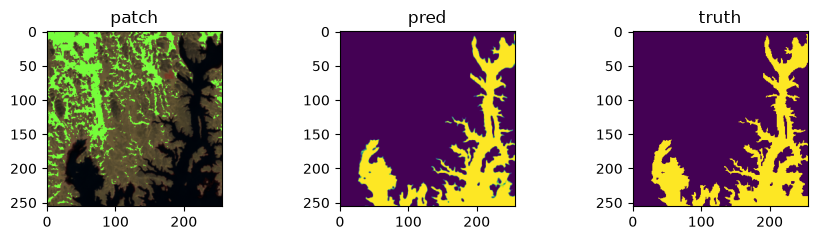

In [21]:
if __name__ == '__main__':
    metrics = train_loops(model=model,  
                    epoches=500,   
                    loss_fn=bce_loss,   
                    optimizer=optimizer,  
                    tra_loader=tra_loader,   
                    val_loader=val_loader,   
                    # lr_scheduler=lr_scheduler,   
                    device=device)   


In [20]:
# torch.save(model.state_dict(), f'model/trained/{model_name}_.pth')
# ## metrics saving
# path_metrics = f'model/trained/{model_name}_training_metrics.csv'   
# metrics_df = pd.DataFrame(metrics)
# metrics_df.to_csv(path_metrics, index=False, sep=',')  
